# Projet Deep Learning : prédire le rendement d'une parcelle (Burkina Faso)

**Problème.** Un agriculteur peut-il estimer le rendement (kg/ha) de sa parcelle selon la culture, la semence (locale ou améliorée), l'engrais, la pluie et la région ?

**Données.** Vraies données : `enquete_agricole_burkina_brut.csv` (enquête agricole, Burkina Faso).

**Modèle.** Un MLP (réseau de neurones à plusieurs couches) en PyTorch. La sortie est un nombre (**régression**), donc pas de sigmoïde à la fin et une perte MSE.

In [1]:
import numpy as np
import pandas as pd
import unicodedata
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

## 1. Chargement et nettoyage des données

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\ouedr\Desktop\Deep Learning\enquete_agricole_burkina_brut .csv")
print("Taille brute :", df.shape)
df.head()

Taille brute : (2930, 21)


,id_parcelle,date_enquete,enqueteur,region,culture,superficie_ha,semence,engrais,quantite_engrais_kg,pluviometrie_mm,...,stockage,pertes_pct,mode_vente,prix_fcfa_kg,sexe_exploitant,age_exploitant,nb_personnes_menage,membre_cooperative,acces_credit,telephone
0,P01956,09/12/2025,E01,Boucle du Mouhoun,Coton,3.6,Améliorée,Urée,365.0,871.0,...,NaN,NaN,Coopérative,275.0,M,80.0,7.0,Non,Non,Oui
1,P02653,03/12/2025,E11,Est,MIL,0.5,Locale,Urée,33.0,723.0,...,Sacs PICS,2.8,Commerçant,190.0,Homme,61.0,10.0,Non,NON,Oui
2,P02282,2025-10-16,E02,Boucle du Mouhoun,Sorgho,0.64,Améliorée,Aucun,0.0,773.0,...,Magasin coopératif,NaN,Autoconsommation,NaN,M,44.0,7.0,Oui,Non,Oui
3,P01496,2025-11-06,E10,Nord,MIL,2.11,Améliorée,Aucun,0.0,833.0,...,Sacs PICS,NaN,Commerçant,160.0,M,52.0,8.0,Oui,Non,Oui
4,P02179,19/12/2025,E06,Centre-Ouest,Sorgho,0.43,Locale,Aucun,0.0,800.0,...,Magasin coopératif,NaN,Autoconsommation,NaN,M,33.0,9.0,Non,Oui,Oui


Le fichier brut contient des problèmes à corriger :
- des **doublons** ;
- des textes écrits de plusieurs façons (`MIL`, `mil`, `Mil` ; `Mais`, `Maïs` ; `BMH`, `Boucle du Mouhoun`...) ;
- des nombres avec une virgule (`1,84`) ;
- des valeurs impossibles (pluie `-1` ou `9999`, rendement énorme).

In [3]:
def norm(s):
    """minuscules, sans espaces autour, sans accents"""
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFD", str(s).strip().lower())
    return "".join(c for c in s if unicodedata.category(c) != "Mn")

df = df.drop_duplicates()

for c in ["region", "culture", "semence", "engrais", "membre_cooperative", "acces_credit"]:
    df[c] = df[c].map(norm)

df["region"] = (df["region"].str.replace(" ", "-")
                .replace({"bmh": "boucle-du-mouhoun", "boucle-mouhoun": "boucle-du-mouhoun"}))

df["superficie_ha"] = pd.to_numeric(df["superficie_ha"].astype(str).str.replace(",", "."), errors="coerce")
df.loc[df["pluviometrie_mm"].isin([-1, 9999]), "pluviometrie_mm"] = np.nan

# On garde les lignes où le rendement (ce qu'on veut prédire) est connu et réaliste
df = df.dropna(subset=["rendement_kg_ha", "culture"])
df = df[(df["rendement_kg_ha"] > 0) & (df["rendement_kg_ha"] <= 6000)]
df = df[((df["superficie_ha"] > 0) & (df["superficie_ha"] < 50)) | df["superficie_ha"].isna()]

print("Taille après nettoyage :", df.shape)
print(df["region"].value_counts().to_dict())
print(df["culture"].value_counts().to_dict())

Taille après nettoyage : (2662, 21)
{'boucle-du-mouhoun': 553, 'hauts-bassins': 551, 'centre-ouest': 411, 'nord': 372, 'centre': 327, 'est': 278, 'sahel': 170}
{'sorgho': 661, 'mais': 592, 'mil': 408, 'coton': 354, 'arachide': 345, 'niebe': 302}


## 2. Choix des variables

**Entrées** (connues *avant* la récolte) : superficie, quantité d'engrais, pluviométrie, région, culture, semence, type d'engrais, coopérative, accès au crédit.

**Sortie** : `rendement_kg_ha`.

On n'utilise **pas** les pertes, le prix ou le mode de vente : ils viennent après la récolte, donc ils ne servent pas à prédire.

In [4]:
num = ["superficie_ha", "quantite_engrais_kg", "pluviometrie_mm"]
cat = ["region", "culture", "semence", "engrais", "membre_cooperative", "acces_credit"]

def preparer(d):
    d = d[num + cat].copy()
    for c in num:
        d[c] = d[c].fillna(d[c].median())      # valeurs manquantes -> médiane
    for c in cat:
        d[c] = d[c].fillna("inconnu")
    d["quantite_engrais_kg"] = np.log1p(d["quantite_engrais_kg"])   # réduit l'effet des très grosses valeurs
    return pd.get_dummies(d, columns=cat, dtype=float)               # texte -> colonnes 0/1

X_df = preparer(df)
y = df["rendement_kg_ha"].values / 1000      # en tonnes/ha, plus facile pour le réseau
print("Nombre d'entrées du réseau :", X_df.shape[1])
X_df.head()

Nombre d'entrées du réseau : 29


,superficie_ha,quantite_engrais_kg,pluviometrie_mm,region_boucle-du-mouhoun,region_centre,region_centre-ouest,region_est,region_hauts-bassins,region_nord,region_sahel,...,engrais_aucun,engrais_compost,engrais_npk,engrais_uree,membre_cooperative_inconnu,membre_cooperative_non,membre_cooperative_oui,acces_credit_inconnu,acces_credit_non,acces_credit_oui
0,3.60,5.902633,871.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.50,3.526361,723.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.64,0.000000,773.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,2.11,0.000000,833.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.43,0.000000,800.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## 3. Séparation entraînement / test et normalisation

On garde 20 % des parcelles **que le modèle ne voit jamais** pendant l'entraînement, pour vérifier qu'il généralise.

In [5]:
n = len(X_df)
idx = np.random.permutation(n)
n_test = int(0.2 * n)
test_idx, train_idx = idx[:n_test], idx[n_test:]

X = X_df.values.astype(np.float32)
mu, sigma = X[train_idx].mean(axis=0), X[train_idx].std(axis=0) + 1e-8
X = (X - mu) / sigma                       # moyenne 0, écart-type 1 (calculés sur l'entraînement)

X_train = torch.tensor(X[train_idx])
y_train = torch.tensor(y[train_idx], dtype=torch.float32).unsqueeze(1)
X_test = torch.tensor(X[test_idx])
y_test = torch.tensor(y[test_idx], dtype=torch.float32).unsqueeze(1)
print("Entraînement :", X_train.shape, " Test :", X_test.shape)

Entraînement : torch.Size([2130, 29])  Test : torch.Size([532, 29])


## 4. Le modèle (MLP)

In [6]:
class MLP(nn.Module):
    def __init__(self, n_entrees):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(n_entrees, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1)            # une seule sortie : le rendement (pas de sigmoïde)
        )

    def forward(self, x):
        return self.reseau(x)

model = MLP(X_train.shape[1])
print(model)

MLP(
  (reseau): Sequential(
    (0): Linear(in_features=29, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 5. Entraînement

À chaque époque : `forward` (prédiction), calcul de la perte MSE, `backward()` (gradients), `step()` (mise à jour des poids), `zero_grad()` (remise à zéro des gradients).

In [7]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

hist_train, hist_test = [], []
for epoch in range(300):
    model.train()
    pred = model(X_train)
    loss = loss_fn(pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        hist_train.append(loss.item())
        hist_test.append(loss_fn(model(X_test), y_test).item())

    if epoch % 50 == 0:
        print(f"Époque {epoch:3d} | perte entraînement {hist_train[-1]:.4f} | perte test {hist_test[-1]:.4f}")

Époque   0 | perte entraînement 2.0605 | perte test 1.6558
Époque  50 | perte entraînement 0.0666 | perte test 0.0749
Époque 100 | perte entraînement 0.0592 | perte test 0.0705
Époque 150 | perte entraînement 0.0565 | perte test 0.0701
Époque 200 | perte entraînement 0.0546 | perte test 0.0707
Époque 250 | perte entraînement 0.0529 | perte test 0.0715


## 6. Évaluation

In [8]:
model.eval()
with torch.no_grad():
    pred_test = model(X_test)

erreur_moyenne = (pred_test - y_test).abs().mean().item() * 1000          # en kg/ha
ss_res = ((y_test - pred_test) ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = (1 - ss_res / ss_tot).item()
base = (y_test - y_train.mean()).abs().mean().item() * 1000

print(f"Erreur moyenne du modèle        : {erreur_moyenne:.0f} kg/ha")
print(f"Erreur si on prédit la moyenne  : {base:.0f} kg/ha")
print(f"R² sur le test                  : {r2:.2f}")

Erreur moyenne du modèle        : 177 kg/ha
Erreur si on prédit la moyenne  : 446 kg/ha
R² sur le test                  : 0.77


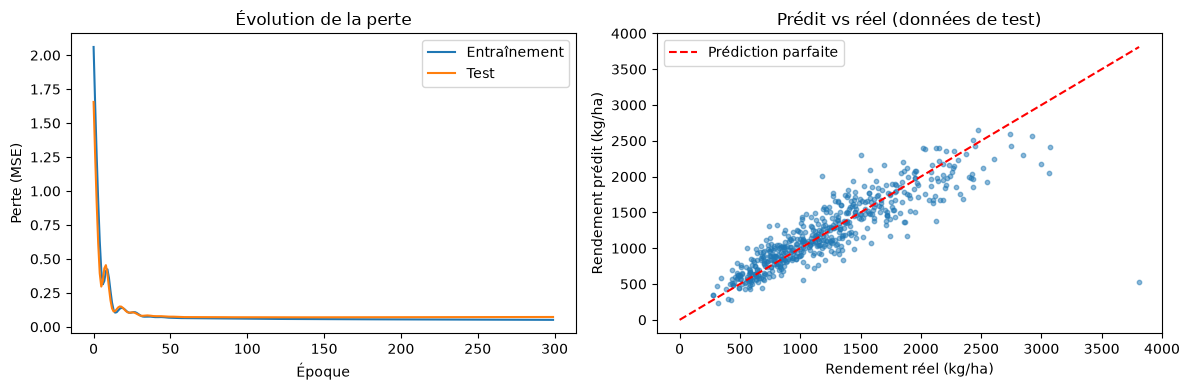

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(hist_train, label="Entraînement")
ax[0].plot(hist_test, label="Test")
ax[0].set_xlabel("Époque"); ax[0].set_ylabel("Perte (MSE)")
ax[0].set_title("Évolution de la perte"); ax[0].legend()

ax[1].scatter(y_test.numpy() * 1000, pred_test.numpy() * 1000, s=10, alpha=0.5)
mx = float(max(y_test.max(), pred_test.max()) * 1000)
ax[1].plot([0, mx], [0, mx], "r--", label="Prédiction parfaite")
ax[1].set_xlabel("Rendement réel (kg/ha)"); ax[1].set_ylabel("Rendement prédit (kg/ha)")
ax[1].set_title("Prédit vs réel (données de test)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Démonstration : semence locale ou améliorée ?

Même parcelle, seule la semence change.

In [10]:
def predire(**p):
    base = {"superficie_ha": 1.0, "quantite_engrais_kg": 0, "pluviometrie_mm": 800,
            "region": "centre", "culture": "mais", "semence": "locale",
            "engrais": "aucun", "membre_cooperative": "non", "acces_credit": "non"}
    base.update(p)
    ligne = pd.DataFrame([base])
    ligne["quantite_engrais_kg"] = np.log1p(ligne["quantite_engrais_kg"])
    ligne = pd.get_dummies(ligne, columns=cat, dtype=float)
    ligne = ligne.reindex(columns=X_df.columns, fill_value=0.0)
    x = torch.tensor(((ligne.values.astype(np.float32) - mu) / sigma))
    model.eval()
    with torch.no_grad():
        return model(x).item() * 1000

for semence in ["locale", "amelioree"]:
    print(f"Maïs, centre, 800 mm, semence {semence:9s} -> {predire(semence=semence):.0f} kg/ha")

print()
for engrais, qte in [("aucun", 0), ("npk", 100)]:
    print(f"Maïs, engrais {engrais:5s} ({qte} kg)        -> {predire(engrais=engrais, quantite_engrais_kg=qte):.0f} kg/ha")

Maïs, centre, 800 mm, semence locale    -> 1618 kg/ha
Maïs, centre, 800 mm, semence amelioree -> 1999 kg/ha

Maïs, engrais aucun (0 kg)        -> 1618 kg/ha
Maïs, engrais npk   (100 kg)        -> 2112 kg/ha


## 8. Sauvegarde du dataset nettoyé et du modèle

On obtient ainsi trois éléments à rendre : le **dataset** (`.csv`), le **modèle** (`.pth`) et le **code** (ce notebook).

In [11]:
# Sauvegarder le dataset nettoyé
df.to_csv("enquete_agricole_nettoyee.csv", index=False)

# Sauvegarder le modèle entraîné
torch.save(model.state_dict(), "modele_rendement.pth")

## 9. Conclusion

- Le modèle prédit le rendement avec une erreur bien plus faible que la simple moyenne.
- La semence améliorée et l'engrais augmentent le rendement prédit, ce qui correspond aux données de l'enquête.
- **Limites** : il s'agit de corrélations (pas de preuve de cause), les données ont été nettoyées de façon simple, et le modèle ne connaît ni le sol, ni les maladies, ni les dates de semis.
- **Suite possible** : plus de variables, un réseau comparé à une simple régression linéaire, une petite application pour les agriculteurs.